In [80]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage.morphology import dilation, disk
from pathlib import Path

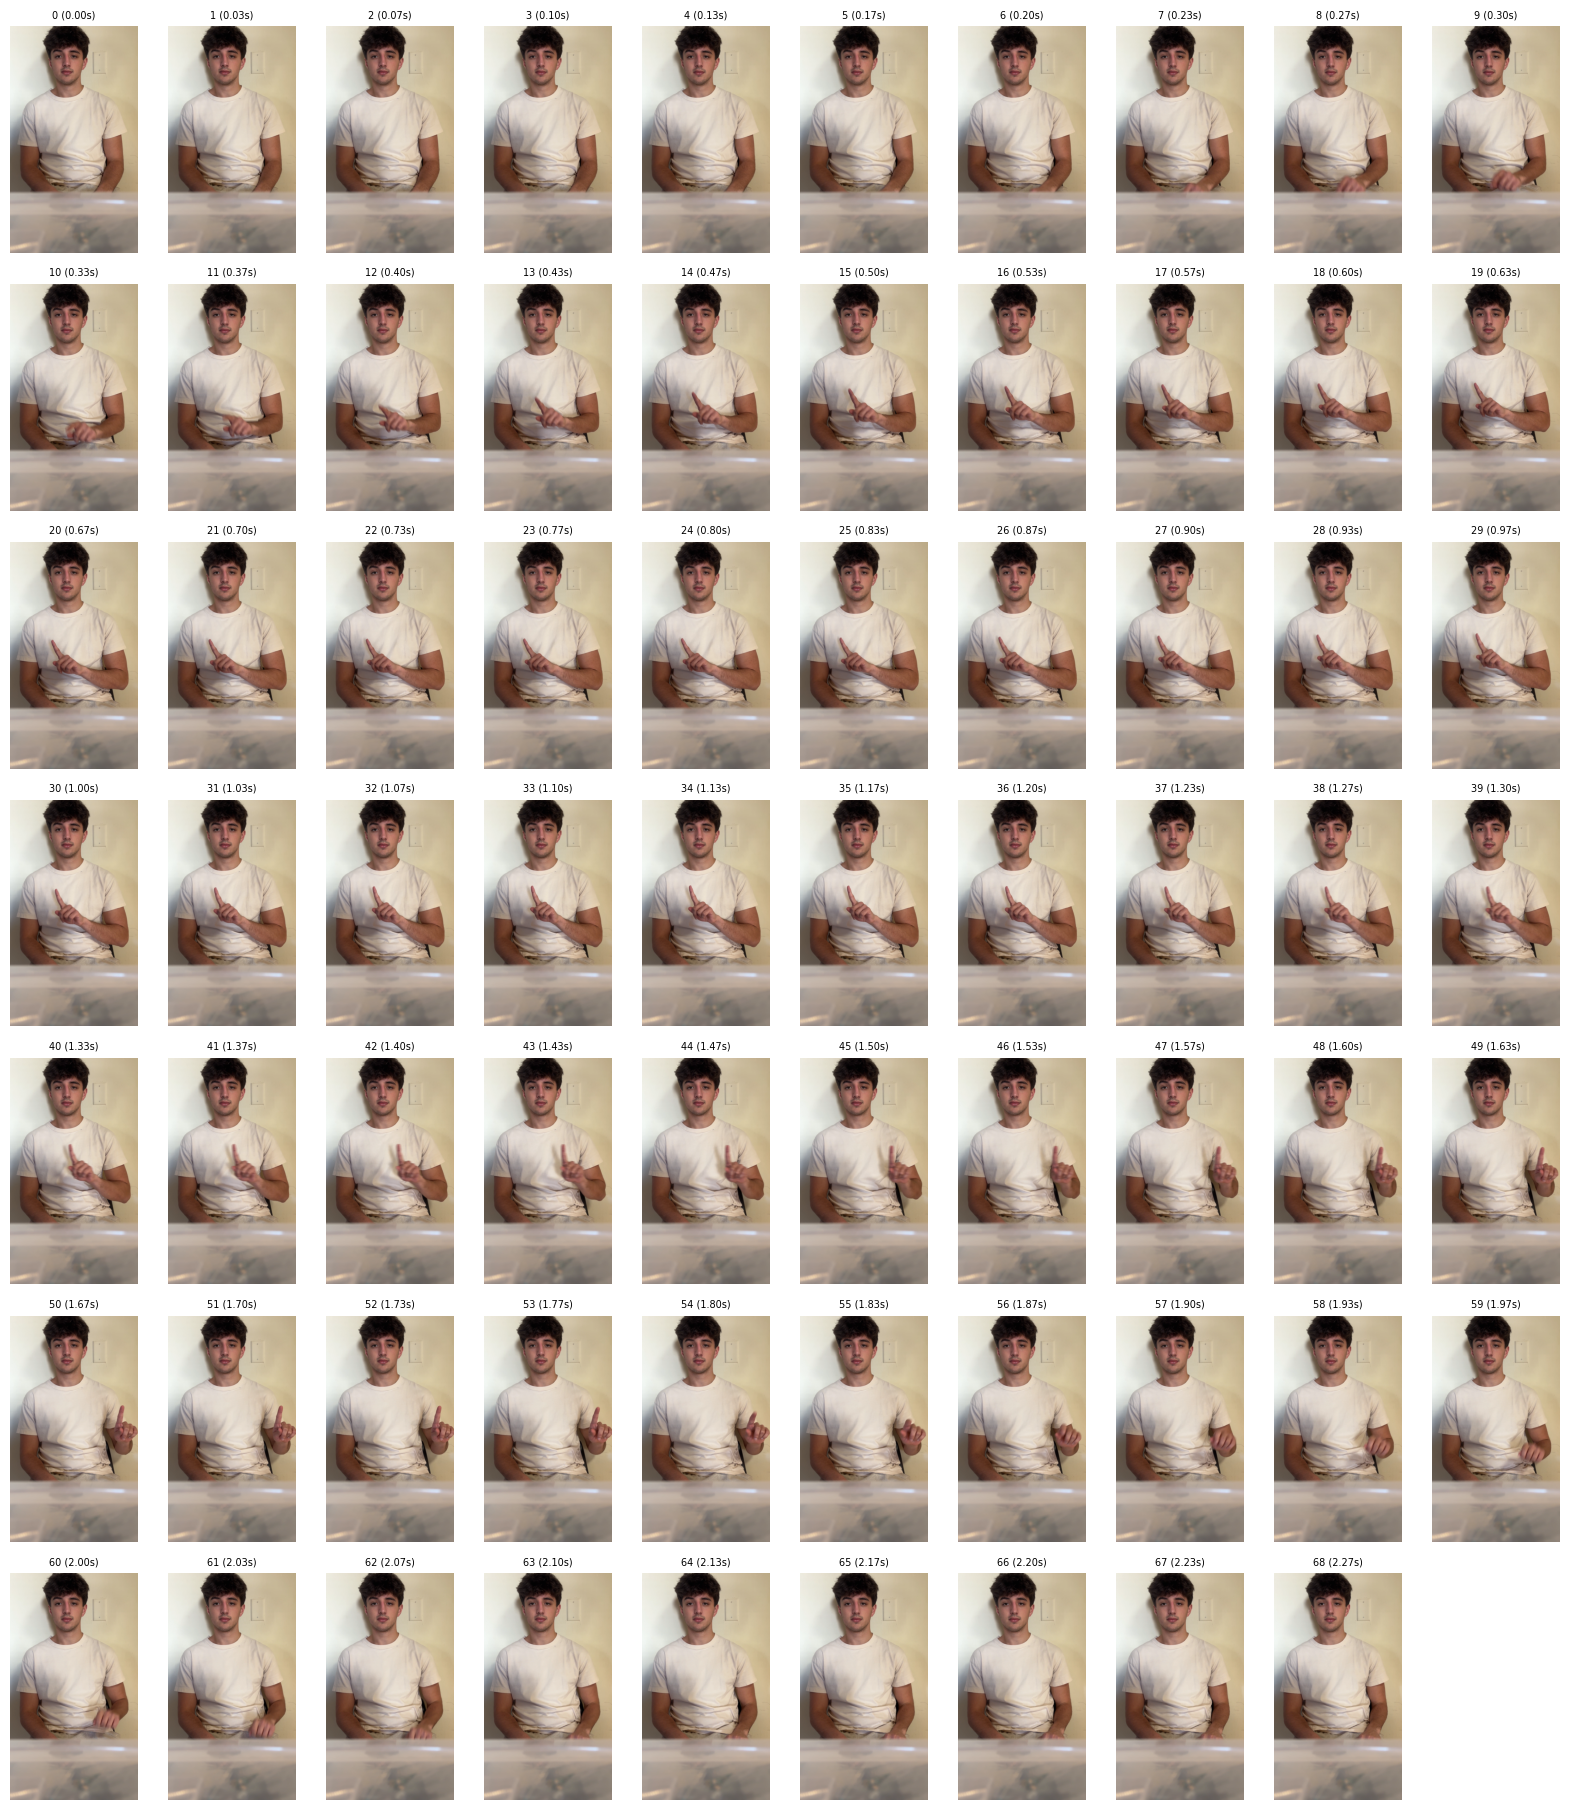

In [46]:
# Convert mp4 video into numpy array for each frame
def load_frames(video_path, scale=0.25):
    capture = cv2.VideoCapture(video_path)
    frames = []

    while True:
        still_frames, frame = capture.read()
        if not still_frames:
            break
        frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        # add to list
        frames.append(frame)
    capture.release()
    return np.stack(frames)

frames = load_frames("../gestures/swipe_left/development/01_swipe_left_01.mp4")

# Display function for testing
def show_frames(frames, cols=10, every=1, fps=30):
    idx = np.arange(0, len(frames), every)
    rows = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 2.6))
    for ax in axes.flat:
        ax.axis("off")
    for ax, i in zip(axes.flat, idx):
        ax.imshow(frames[i], cmap="gray", vmin=0, vmax=255)
        ax.set_title(f"{i} ({i/fps:.2f}s)", fontsize=7)
    plt.tight_layout()
    plt.savefig("diff_grid.png", dpi=100)
    plt.show()
    
#show_frames(frames[..., ::-1]) # opencv is BGR instead of RGB, change it.
    

In [73]:
# Skin Mask: Image differencing was picking up too much from shirt movement, so first create a mask that only contains
# the skin color. Only differncing on this mask will isolate the hand movement.
def skin_mask(frames):
    masks = []
    for frame in frames:
        ycc = cv2.cvtColor(frame, cv2.COLOR_BGR2YCrCb)
        masks.append(cv2.inRange(ycc, (0, 145, 100), (255, 175, 122))) # only keep a general band for skin color
    return np.stack(masks)
skin = skin_mask(frames)
#show_frames(skin)

gray = np.stack([cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) for frame in frames]).astype(np.int16)
# Now use temporal differencing (i.e. use last frame as background).
def temporal_differencing(gray, skin, frames):
    T = 15
    diff_masks = []
    for i in range (1,frames.shape[0]):
        diff = gray[i]-gray[i-1] > T
        is_skin = (skin[i]>0) | (skin[i-1]>0)
        diff_masks.append((diff & is_skin).astype(np.uint8) * 255)
    # Slight dilation to make MHI a little cleaner
    diff_masks = np.stack([dilation(mask, disk(1)) for mask in diff_masks])
    return diff_masks
diff_masks = temporal_differencing(gray,skin,frames)
#show_frames(diff_masks)

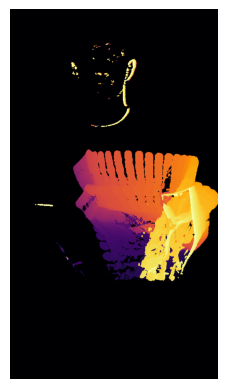

In [76]:
def mhi(masks):
    max = len(masks)
    history = np.zeros(masks.shape[1:],np.float32)
    for mask in masks:
        is_moving = mask > 0
        # Set current motion to max
        history[is_moving] = max 
        # Fade everything else by one
        history[~is_moving] = np.maximum(history[~is_moving]-1,0) 
    return (history / max * 255).astype(np.uint8)

MHI = mhi(diff_masks)

plt.imshow(mhi, cmap="inferno")     
plt.axis("off")
plt.show()


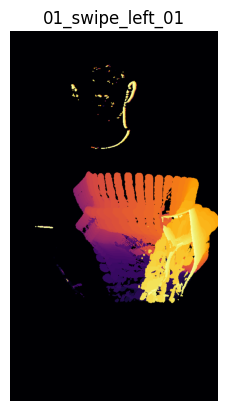

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(960, 540), dtype=uint8)

In [81]:
# Create an all in one function
def mhi_from_video(video_path,show=True):
    frames = load_frames(video_path)
    skin = skin_mask(frames)
    gray = np.stack([cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY) for frame in frames]).astype(np.int16)
    diff_masks = temporal_differencing(gray, skin, frames)
    MHI = mhi(diff_masks)
    if show:
        plt.imshow(MHI, cmap="inferno")    
        plt.title(Path(video_path).stem)
        plt.axis("off")
        plt.show()
    return MHI
mhi_from_video("../gestures/swipe_left/development/01_swipe_left_01.mp4")

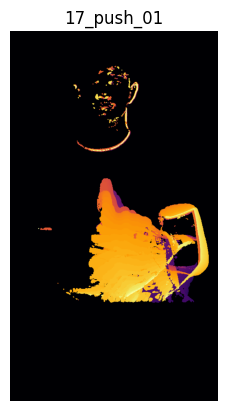

push         17_push_01.mp4 -> ../mhi/push/17_push_01.png


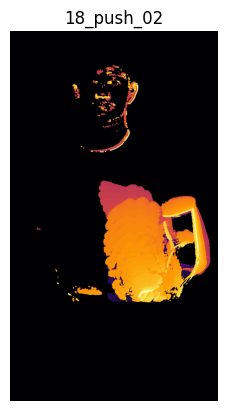

push         18_push_02.mp4 -> ../mhi/push/18_push_02.png


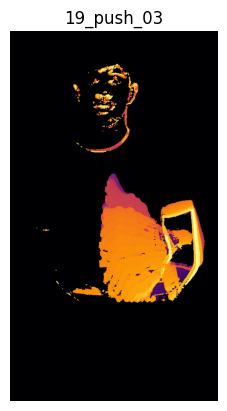

push         19_push_03.mp4 -> ../mhi/push/19_push_03.png


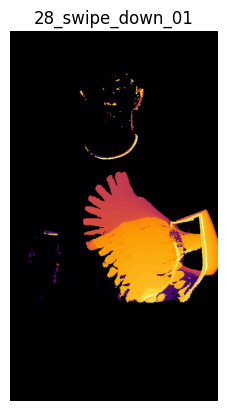

swipe_down   28_swipe_down_01.mp4 -> ../mhi/swipe_down/28_swipe_down_01.png


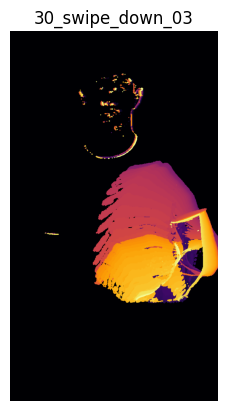

swipe_down   30_swipe_down_03.mp4 -> ../mhi/swipe_down/30_swipe_down_03.png


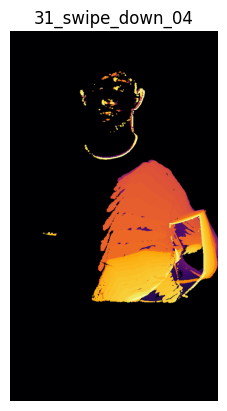

swipe_down   31_swipe_down_04.mp4 -> ../mhi/swipe_down/31_swipe_down_04.png


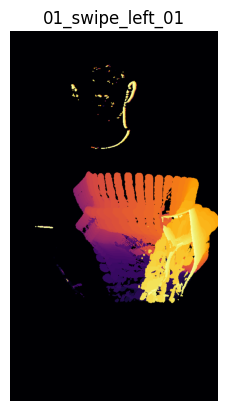

swipe_left   01_swipe_left_01.mp4 -> ../mhi/swipe_left/01_swipe_left_01.png


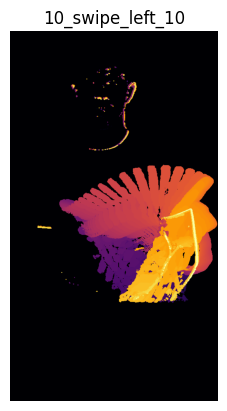

swipe_left   10_swipe_left_10.mp4 -> ../mhi/swipe_left/10_swipe_left_10.png


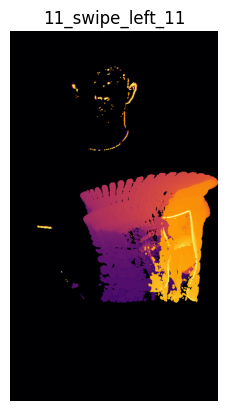

swipe_left   11_swipe_left_11.mp4 -> ../mhi/swipe_left/11_swipe_left_11.png


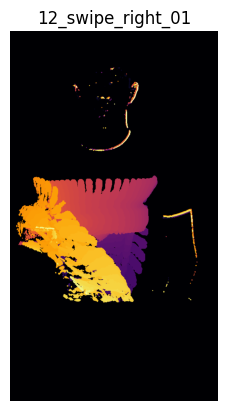

swipe_right  12_swipe_right_01.mp4 -> ../mhi/swipe_right/12_swipe_right_01.png


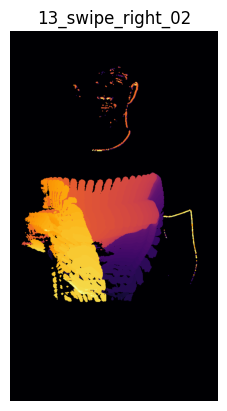

swipe_right  13_swipe_right_02.mp4 -> ../mhi/swipe_right/13_swipe_right_02.png


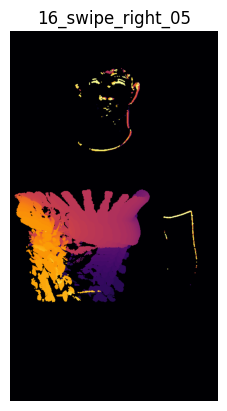

swipe_right  16_swipe_right_05.mp4 -> ../mhi/swipe_right/16_swipe_right_05.png


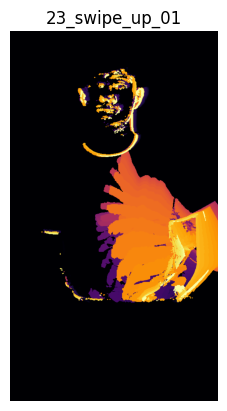

swipe_up     23_swipe_up_01.mp4 -> ../mhi/swipe_up/23_swipe_up_01.png


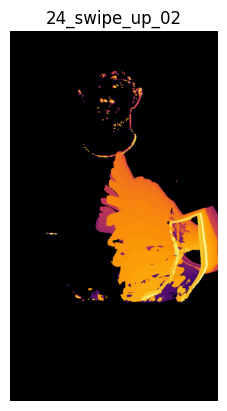

swipe_up     24_swipe_up_02.mp4 -> ../mhi/swipe_up/24_swipe_up_02.png


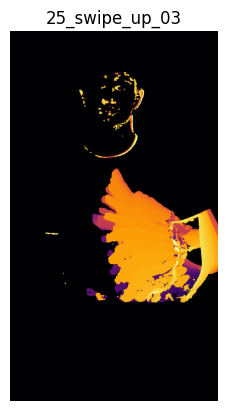

swipe_up     25_swipe_up_03.mp4 -> ../mhi/swipe_up/25_swipe_up_03.png


In [82]:
# Now loop through the development gestures and create MHI for each one
Gesture_Folder = Path("../gestures")
MHI_Folder = Path("../mhi")

for video in sorted(Gesture_Folder.glob("*/development/*.mp4")):
    gesture = video.parent.parent.name
    out_dir = MHI_Folder / gesture
    out_dir.mkdir(parents=True, exist_ok=True)

    MHI = mhi_from_video(video)
    out_path = out_dir / f"{video.stem}.png"
    color = cv2.applyColorMap(MHI, cv2.COLORMAP_INFERNO)
    cv2.imwrite(str(out_path),MHI)
    print(f"{gesture:12s} {video.name} -> {out_path}")
    